In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('ETH_1h.csv')

In [4]:
df.head()

,Date,Symbol,Open,High,Low,Close,Volume
0,2020-03-13 08-PM,ETHUSD,129.94,131.82,126.87,128.71,1940673.93
1,2020-03-13 07-PM,ETHUSD,119.51,132.02,117.10,129.94,7579741.09
2,2020-03-13 06-PM,ETHUSD,124.47,124.85,115.50,119.51,4898735.81
3,2020-03-13 05-PM,ETHUSD,124.08,127.42,121.63,124.47,2753450.92
4,2020-03-13 04-PM,ETHUSD,124.85,129.51,120.17,124.08,4461424.71


In [5]:
df.shape

(23674, 7)

# DateTime

In [6]:
df.loc[0, 'Date']

'2020-03-13 08-PM'

In [8]:
# Day Name
df.loc[0, 'Date'].day_name()

AttributeError: 'str' object has no attribute 'day_name'

In [9]:
df['Date']=pd.to_datetime(df['Date'])

C:\Users\Shreyansh kumar\AppData\Local\Temp\ipykernel_21004\3023999556.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date']=pd.to_datetime(df['Date'])


DateParseError: Unknown datetime string format, unable to parse: 2020-03-13 08-PM

# Parse DateTime

In [10]:
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d %I-%p')

In [11]:
df['Date']

0       2020-03-13 20:00:00
1       2020-03-13 19:00:00
2       2020-03-13 18:00:00
3       2020-03-13 17:00:00
4       2020-03-13 16:00:00
                ...        
23669   2017-07-01 15:00:00
23670   2017-07-01 14:00:00
23671   2017-07-01 13:00:00
23672   2017-07-01 12:00:00
23673   2017-07-01 11:00:00
Name: Date, Length: 23674, dtype: datetime64[us]

# Run DateTime

In [12]:
df.loc[0, 'Date'].day_name()

'Friday'

# Parse Date

In [13]:
df = pd.read_csv(
    'ETH_1h.csv',
    parse_dates=['Date'],
    date_format='%Y-%m-%d %I-%p'
)
df.head()

,Date,Symbol,Open,High,Low,Close,Volume
0,2020-03-13 20:00:00,ETHUSD,129.94,131.82,126.87,128.71,1940673.93
1,2020-03-13 19:00:00,ETHUSD,119.51,132.02,117.10,129.94,7579741.09
2,2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81
3,2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92
4,2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71


# Run DateTime method on Series

In [14]:
# Example:We want to know the day name of entire date column
df['Date'].dt.day_name()

0          Friday
1          Friday
2          Friday
3          Friday
4          Friday
           ...   
23669    Saturday
23670    Saturday
23671    Saturday
23672    Saturday
23673    Saturday
Name: Date, Length: 23674, dtype: str

# dt class on series

In [15]:
# Example: We want to create a another column so that we can take reference what day all off these trades took place
df['DayOfWeek']=df['Date'].dt.day_name()
df

,Date,Symbol,Open,High,Low,Close,Volume,DayOfWeek
0,2020-03-13 20:00:00,ETHUSD,129.94,131.82,126.87,128.71,1940673.93,Friday
1,2020-03-13 19:00:00,ETHUSD,119.51,132.02,117.10,129.94,7579741.09,Friday
2,2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81,Friday
3,2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92,Friday
4,2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71,Friday
...,...,...,...,...,...,...,...,...
23669,2017-07-01 15:00:00,ETHUSD,265.74,272.74,265.00,272.57,1500282.55,Saturday
23670,2017-07-01 14:00:00,ETHUSD,268.79,269.90,265.00,265.74,1702536.85,Saturday
23671,2017-07-01 13:00:00,ETHUSD,274.83,274.93,265.00,268.79,3010787.99,Saturday
23672,2017-07-01 12:00:00,ETHUSD,275.01,275.01,271.00,274.83,824362.87,Saturday


# Exploring the Data

In [16]:
# Example: Earliest and latest dates
df['Date'].min()

Timestamp('2017-07-01 11:00:00')

In [17]:
df['Date'].max()

Timestamp('2020-03-13 20:00:00')

# Time Delta

In [18]:
# Time Delta is the difference between the date to view the time
df['Date'].max() - df['Date'].min()

Timedelta('986 days 09:00:00')

# Filters by Date

In [19]:
# Example: Data for 2020
filt = (df['Date'] >= '2020')
df.loc[filt]

,Date,Symbol,Open,High,Low,Close,Volume,DayOfWeek
0,2020-03-13 20:00:00,ETHUSD,129.94,131.82,126.87,128.71,1940673.93,Friday
1,2020-03-13 19:00:00,ETHUSD,119.51,132.02,117.10,129.94,7579741.09,Friday
2,2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81,Friday
3,2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92,Friday
4,2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71,Friday
...,...,...,...,...,...,...,...,...
1744,2020-01-01 04:00:00,ETHUSD,129.57,130.00,129.50,129.56,702786.82,Wednesday
1745,2020-01-01 03:00:00,ETHUSD,130.37,130.44,129.38,129.57,496704.23,Wednesday
1746,2020-01-01 02:00:00,ETHUSD,130.14,130.50,129.91,130.37,396315.72,Wednesday
1747,2020-01-01 01:00:00,ETHUSD,128.34,130.14,128.32,130.14,635419.40,Wednesday


In [20]:
filt = (df['Date'] >= '2019') & (df['Date'] < '2020')
df.loc[filt]

,Date,Symbol,Open,High,Low,Close,Volume,DayOfWeek
1749,2019-12-31 23:00:00,ETHUSD,128.33,128.69,128.14,128.54,440678.91,Tuesday
1750,2019-12-31 22:00:00,ETHUSD,128.38,128.69,127.95,128.33,554646.02,Tuesday
1751,2019-12-31 21:00:00,ETHUSD,127.86,128.43,127.72,128.38,350155.69,Tuesday
1752,2019-12-31 20:00:00,ETHUSD,127.84,128.34,127.71,127.86,428183.38,Tuesday
1753,2019-12-31 19:00:00,ETHUSD,128.69,128.69,127.60,127.84,1169847.84,Tuesday
...,...,...,...,...,...,...,...,...
10504,2019-01-01 04:00:00,ETHUSD,130.75,133.96,130.74,131.96,2791135.37,Tuesday
10505,2019-01-01 03:00:00,ETHUSD,130.06,130.79,130.06,130.75,503732.63,Tuesday
10506,2019-01-01 02:00:00,ETHUSD,130.79,130.88,129.55,130.06,838183.43,Tuesday
10507,2019-01-01 01:00:00,ETHUSD,131.62,131.62,130.77,130.79,434917.99,Tuesday


# Filter by Month and Date

In [21]:
filt = (df['Date']>=pd.to_datetime('2019-01-01')) & (df['Date']<pd.to_datetime('2020-01-01'))
df.loc[filt]

,Date,Symbol,Open,High,Low,Close,Volume,DayOfWeek
1749,2019-12-31 23:00:00,ETHUSD,128.33,128.69,128.14,128.54,440678.91,Tuesday
1750,2019-12-31 22:00:00,ETHUSD,128.38,128.69,127.95,128.33,554646.02,Tuesday
1751,2019-12-31 21:00:00,ETHUSD,127.86,128.43,127.72,128.38,350155.69,Tuesday
1752,2019-12-31 20:00:00,ETHUSD,127.84,128.34,127.71,127.86,428183.38,Tuesday
1753,2019-12-31 19:00:00,ETHUSD,128.69,128.69,127.60,127.84,1169847.84,Tuesday
...,...,...,...,...,...,...,...,...
10504,2019-01-01 04:00:00,ETHUSD,130.75,133.96,130.74,131.96,2791135.37,Tuesday
10505,2019-01-01 03:00:00,ETHUSD,130.06,130.79,130.06,130.75,503732.63,Tuesday
10506,2019-01-01 02:00:00,ETHUSD,130.79,130.88,129.55,130.06,838183.43,Tuesday
10507,2019-01-01 01:00:00,ETHUSD,131.62,131.62,130.77,130.79,434917.99,Tuesday


# Setting an Index

In [22]:
df.set_index('Date', inplace=True)

In [23]:
df.sort_index(inplace=True)

In [24]:
df

,Symbol,Open,High,Low,Close,Volume,DayOfWeek
Date,,,,,,,
2017-07-01 11:00:00,ETHUSD,279.98,279.99,272.10,275.01,679358.87,Saturday
2017-07-01 12:00:00,ETHUSD,275.01,275.01,271.00,274.83,824362.87,Saturday
2017-07-01 13:00:00,ETHUSD,274.83,274.93,265.00,268.79,3010787.99,Saturday
2017-07-01 14:00:00,ETHUSD,268.79,269.90,265.00,265.74,1702536.85,Saturday
2017-07-01 15:00:00,ETHUSD,265.74,272.74,265.00,272.57,1500282.55,Saturday
...,...,...,...,...,...,...,...
2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71,Friday
2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92,Friday
2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81,Friday


In [25]:
df.loc['2019']

,Symbol,Open,High,Low,Close,Volume,DayOfWeek
Date,,,,,,,
2019-01-01 00:00:00,ETHUSD,130.53,131.91,130.48,131.62,1067136.21,Tuesday
2019-01-01 01:00:00,ETHUSD,131.62,131.62,130.77,130.79,434917.99,Tuesday
2019-01-01 02:00:00,ETHUSD,130.79,130.88,129.55,130.06,838183.43,Tuesday
2019-01-01 03:00:00,ETHUSD,130.06,130.79,130.06,130.75,503732.63,Tuesday
2019-01-01 04:00:00,ETHUSD,130.75,133.96,130.74,131.96,2791135.37,Tuesday
...,...,...,...,...,...,...,...
2019-12-31 19:00:00,ETHUSD,128.69,128.69,127.60,127.84,1169847.84,Tuesday
2019-12-31 20:00:00,ETHUSD,127.84,128.34,127.71,127.86,428183.38,Tuesday
2019-12-31 21:00:00,ETHUSD,127.86,128.43,127.72,128.38,350155.69,Tuesday


# Using Slice

In [26]:
# Grabbing specific dates

In [27]:
# Example: getting the data for jan2020 and feb2020
df['2020-01':'2020-02']

,Symbol,Open,High,Low,Close,Volume,DayOfWeek
Date,,,,,,,
2020-01-01 00:00:00,ETHUSD,128.54,128.54,128.12,128.34,245119.91,Wednesday
2020-01-01 01:00:00,ETHUSD,128.34,130.14,128.32,130.14,635419.40,Wednesday
2020-01-01 02:00:00,ETHUSD,130.14,130.50,129.91,130.37,396315.72,Wednesday
2020-01-01 03:00:00,ETHUSD,130.37,130.44,129.38,129.57,496704.23,Wednesday
2020-01-01 04:00:00,ETHUSD,129.57,130.00,129.50,129.56,702786.82,Wednesday
...,...,...,...,...,...,...,...
2020-02-29 19:00:00,ETHUSD,225.09,225.85,223.87,225.31,1250856.20,Saturday
2020-02-29 20:00:00,ETHUSD,225.31,225.33,223.50,224.63,511648.65,Saturday
2020-02-29 21:00:00,ETHUSD,224.63,225.14,222.74,223.48,561158.03,Saturday


# Analyzing Data

In [28]:
# Example:we wanted to get the average closing price for aetherium for all of our rows of these dates
df['2020-01':'2020-02']['Close'].mean()

np.float64(195.1655902777778)

# Data Viewing

In [29]:
df['2020-01':'2020-02'].head(24)

,Symbol,Open,High,Low,Close,Volume,DayOfWeek
Date,,,,,,,
2020-01-01 00:00:00,ETHUSD,128.54,128.54,128.12,128.34,245119.91,Wednesday
2020-01-01 01:00:00,ETHUSD,128.34,130.14,128.32,130.14,635419.40,Wednesday
2020-01-01 02:00:00,ETHUSD,130.14,130.50,129.91,130.37,396315.72,Wednesday
2020-01-01 03:00:00,ETHUSD,130.37,130.44,129.38,129.57,496704.23,Wednesday
2020-01-01 04:00:00,ETHUSD,129.57,130.00,129.50,129.56,702786.82,Wednesday
2020-01-01 05:00:00,ETHUSD,129.56,129.94,129.47,129.83,232163.70,Wednesday
2020-01-01 06:00:00,ETHUSD,129.83,130.25,129.82,130.00,118328.64,Wednesday
2020-01-01 07:00:00,ETHUSD,130.00,130.25,129.80,129.87,112620.14,Wednesday
2020-01-01 08:00:00,ETHUSD,129.87,130.01,129.61,130.01,134231.17,Wednesday


In [30]:
df.loc['2020-01-01']['High']

Date
2020-01-01 00:00:00    128.54
2020-01-01 01:00:00    130.14
2020-01-01 02:00:00    130.50
2020-01-01 03:00:00    130.44
2020-01-01 04:00:00    130.00
2020-01-01 05:00:00    129.94
2020-01-01 06:00:00    130.25
2020-01-01 07:00:00    130.25
2020-01-01 08:00:00    130.01
2020-01-01 09:00:00    130.22
2020-01-01 10:00:00    130.33
2020-01-01 11:00:00    131.42
2020-01-01 12:00:00    131.31
2020-01-01 13:00:00    132.08
2020-01-01 14:00:00    132.05
2020-01-01 15:00:00    132.15
2020-01-01 16:00:00    132.56
2020-01-01 17:00:00    132.68
2020-01-01 18:00:00    132.14
2020-01-01 19:00:00    131.72
2020-01-01 20:00:00    131.87
2020-01-01 21:00:00    131.99
2020-01-01 22:00:00    131.41
2020-01-01 23:00:00    130.27
Name: High, dtype: float64

# Max Day viewing

In [31]:
df.loc['2020-01-01']['High'].max()

np.float64(132.68)

# Resampling

In [32]:
# Example:Resampling Data by day
df['High'].resample('D').max()

Date
2017-07-01    279.99
2017-07-02    293.73
2017-07-03    285.00
2017-07-04    282.83
2017-07-05    274.97
               ...  
2020-03-09    208.65
2020-03-10    206.28
2020-03-11    202.98
2020-03-12    195.64
2020-03-13    148.00
Freq: D, Name: High, Length: 987, dtype: float64

# Saving Series

In [33]:
highs = df['High'].resample('D').max()
highs['2020-01-01']

np.float64(132.68)

# Installing Matplotlib

In [34]:
%matplotlib inline

<Axes: xlabel='Date'>

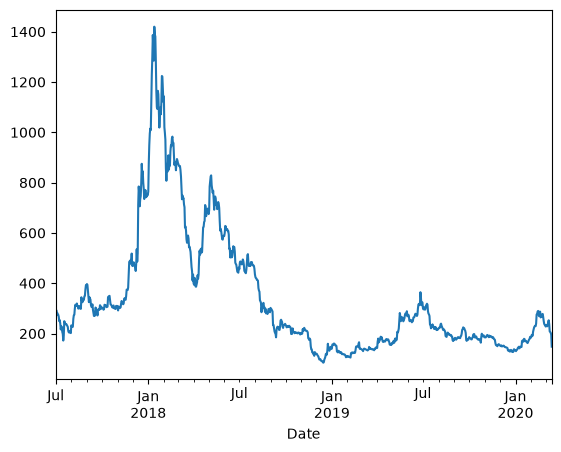

In [35]:
highs.plot()

# Resample By Day

In [40]:
# Daily average
df.resample('D').mean(numeric_only=True)

,Open,High,Low,Close,Volume
Date,,,,,
2017-07-01,266.581538,268.698462,261.861538,265.284615,2.198771e+06
2017-07-02,268.870833,272.438750,266.422083,269.782500,2.177595e+06
2017-07-03,279.241667,280.774167,276.599583,278.882083,1.459015e+06
2017-07-04,277.042083,278.034167,275.117500,276.743333,1.254579e+06
2017-07-05,265.147917,267.120000,262.834583,265.025833,1.797923e+06
...,...,...,...,...,...
2020-03-09,200.680417,203.311667,197.860000,200.818333,3.804752e+06
2020-03-10,201.672083,203.155000,199.912500,201.577500,1.553063e+06
2020-03-11,196.155833,197.684167,194.100833,195.910417,1.894868e+06


In [41]:
# Weekly average
df.resample('W').mean(numeric_only=True)

,Open,High,Low,Close,Volume
Date,,,,,
2017-07-02,268.066486,271.124595,264.819730,268.202162,2.185035e+06
2017-07-09,261.337024,262.872917,259.186190,261.062083,1.337349e+06
2017-07-16,196.193214,199.204405,192.722321,195.698393,2.986756e+06
2017-07-23,212.351429,215.779286,209.126310,212.783750,4.298593e+06
2017-07-30,203.496190,205.110357,201.714048,203.309524,1.581729e+06
...,...,...,...,...,...
2020-02-16,255.021667,257.255238,252.679762,255.198452,2.329087e+06
2020-02-23,265.220833,267.263690,262.948512,265.321905,1.826094e+06
2020-03-01,236.720536,238.697500,234.208750,236.373988,2.198762e+06


In [42]:
df.resample('ME').mean(numeric_only=True)

,Open,High,Low,Close,Volume
Date,,,,,
2017-07-31,220.118963,222.516126,217.489018,220.010969,2.480603e+06
2017-08-31,298.258616,300.082661,296.421465,298.511815,2.056356e+06
2017-09-30,298.656472,301.120875,295.837278,298.524639,2.331871e+06
2017-10-31,305.642594,306.866976,304.328159,305.649772,1.096153e+06
2017-11-30,355.471236,357.946500,353.141028,355.646292,2.741744e+06
2017-12-31,629.484960,636.534435,621.435081,629.898011,6.952835e+06
2018-01-31,1083.552487,1096.335121,1068.435242,1084.040390,1.038829e+07
2018-02-28,872.477783,880.735893,862.989390,872.098304,6.135724e+06
2018-03-31,630.316505,634.618750,625.060524,629.704341,2.726483e+06


In [44]:
df.resample('W').agg({'Close': 'mean', 'High': 'max', 'Low': 'min', 'Volume':'sum'})

,Close,High,Low,Volume
Date,,,,
2017-07-02,268.202162,293.73,253.23,8.084631e+07
2017-07-09,261.062083,285.00,231.25,2.246746e+08
2017-07-16,195.698393,240.33,130.26,5.017750e+08
2017-07-23,212.783750,249.40,153.25,7.221637e+08
2017-07-30,203.309524,229.99,178.03,2.657305e+08
...,...,...,...,...
2020-02-16,255.198452,290.00,216.31,3.912867e+08
2020-02-23,265.321905,287.13,242.36,3.067838e+08
2020-03-01,236.373988,278.13,209.26,3.693920e+08
